Train rows 15245 (419 cells), test rows 9959 (418 cells)
subset
seen_cell               8615
new_region               722
new_cell_seen_region     622
Spatial tuning folds: 8;  leave-region-out regions: ['Emilia-Romagna', 'Friuli-Venezia Giulia', 'Lazio', 'Lombardy', 'Piedmont', 'Tuscany', 'Veneto']
Stages: {'0_season': 1, '1_topo': 3, '2_climate_core': 6, '3_landcover_comp': 11, '4_water': 13, '5_climate_extra': 18, 'X_static_only': 10, 'X_climate_only': 9, 'X_clc16_for_comp': 24, 'X_core_plus_clc16': 27, 'X_coords_baseline': 3, 'L_minus_topo': 16, 'L_minus_climate_core': 15, 'L_minus_landcover_comp': 13, 'L_minus_water': 16, 'L_minus_climate_extra': 13}
   ↷ cached: XGBoost | 0_season
   ↷ cached: XGBoost | 1_topo
   ↷ cached: XGBoost | 2_climate_core
   ↷ cached: XGBoost | 3_landcover_comp
   ↷ cached: XGBoost | 4_water
   ↷ cached: XGBoost | 5_climate_extra
   ↷ cached: XGBoost | X_static_only
   ↷ cached: XGBoost | X_climate_only
   ↷ cached: XGBoost | X_clc16_for_comp
   ↷ cached

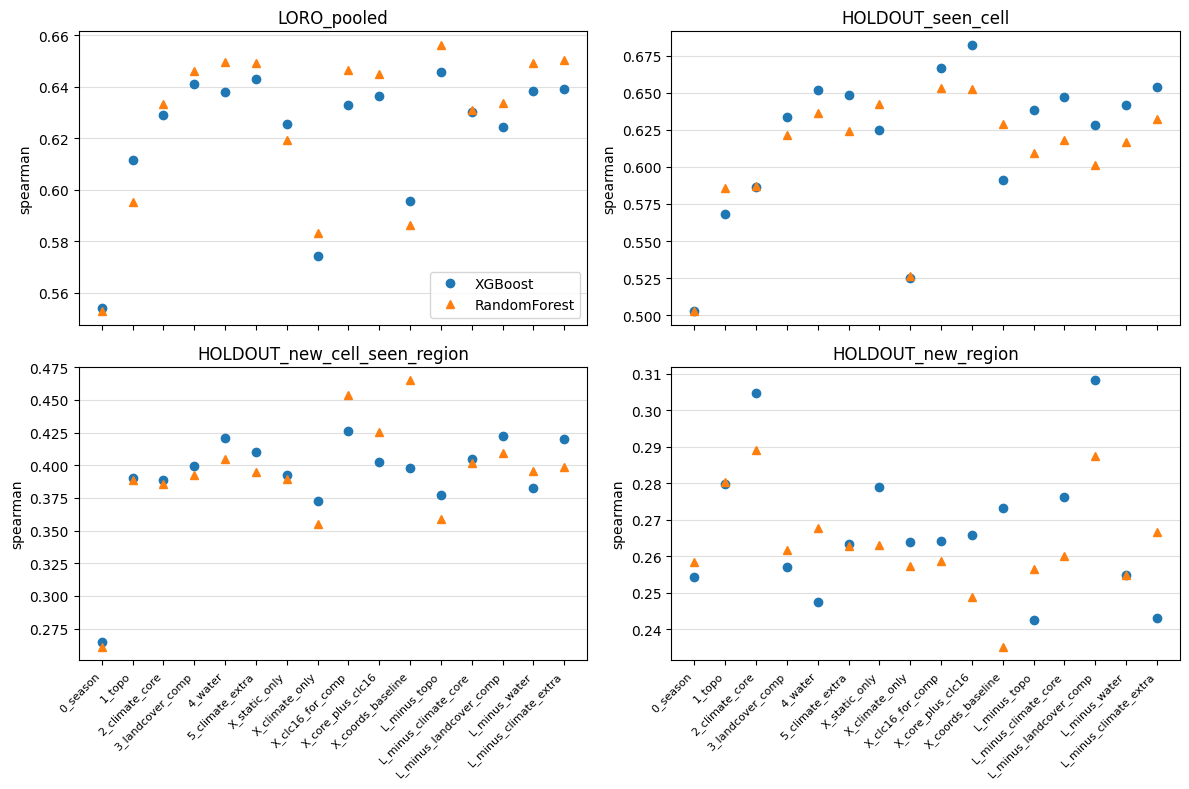

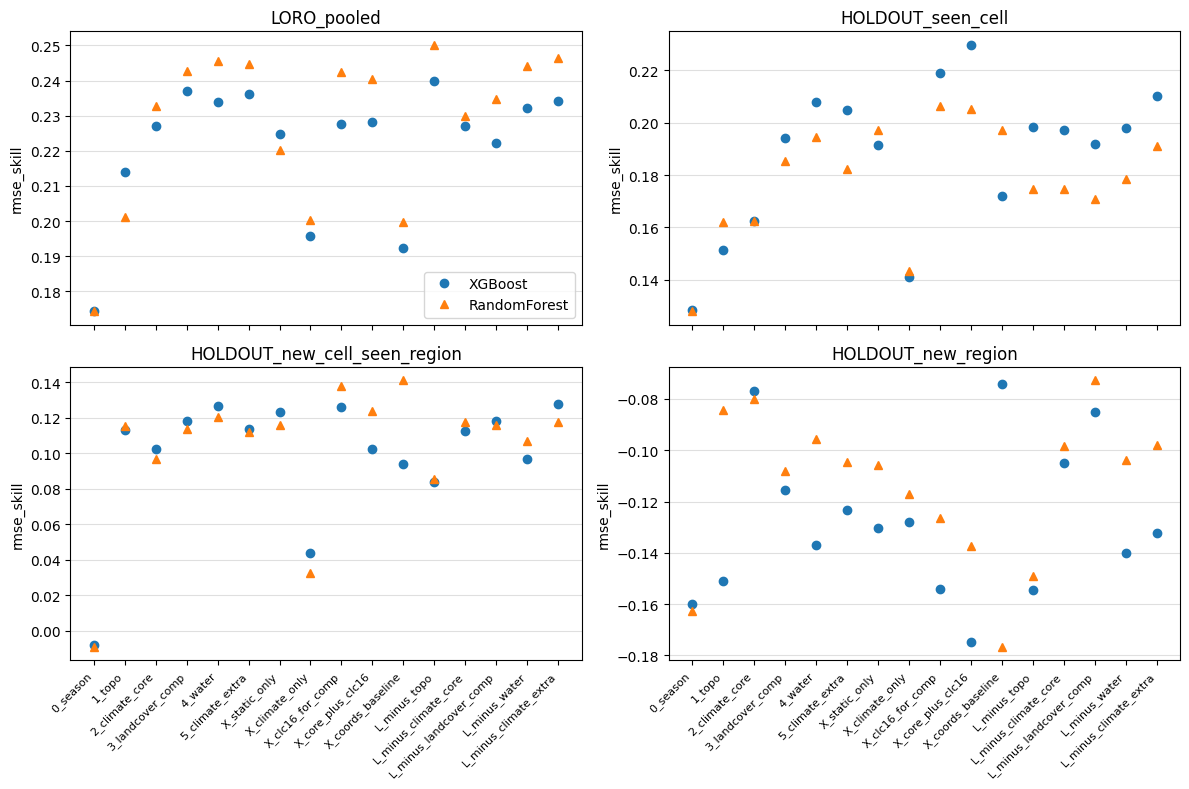

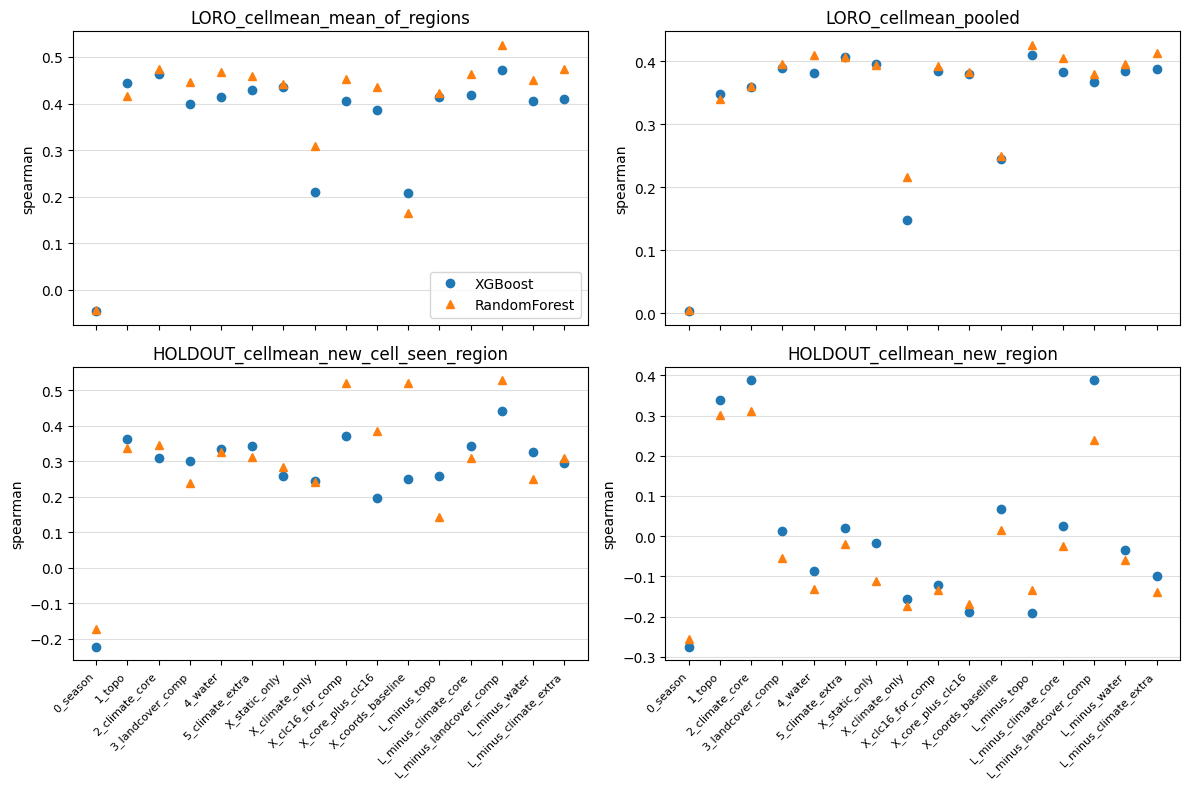

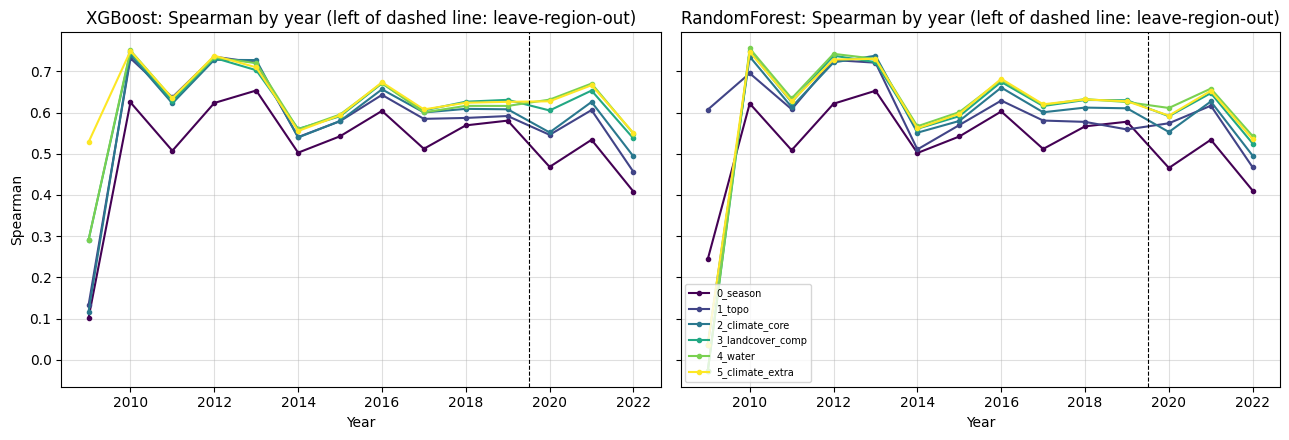


Spearman, LORO_cellmean_mean_of_regions:
model                   RandomForest  XGBoost
stage                                        
0_season                      -0.044   -0.047
1_topo                         0.416    0.445
2_climate_core                 0.474    0.464
3_landcover_comp               0.447    0.399
4_water                        0.469    0.415
5_climate_extra                0.459    0.430
X_static_only                  0.443    0.435
X_climate_only                 0.309    0.210
X_clc16_for_comp               0.452    0.406
X_core_plus_clc16              0.436    0.386
X_coords_baseline              0.165    0.207
L_minus_topo                   0.423    0.414
L_minus_climate_core           0.463    0.417
L_minus_landcover_comp         0.526    0.471
L_minus_water                  0.451    0.405
L_minus_climate_extra          0.475    0.410

Spearman, LORO_cellmean_pooled:
model                   RandomForest  XGBoost
stage                                        
0_sea

In [5]:
"""
Culex pipiens challenge: feature-group ablation with XGBoost and RandomForest.

Adapted from the WNV ablation pipeline (Optuna + spatial block CV + cached params), changed for:
  * a regression target (log1p of weekly count) on a cell-week table,
  * feature GROUPS (from feature_groups.json written by culex_prep_features.py) instead of quarter/stage files,
  * leave-region-out CV as the headline spatial test,
  * a 2020-2022 holdout reported separately for seen cells, new cells in seen regions, and new regions.

Run:  python culex_ablation.py      (resumable: finished (model, stage) runs are cached)
"""
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import xgboost as xgb
import optuna
import verde as vd
import matplotlib.pyplot as plt
from optuna.samplers import TPESampler
from joblib import Parallel, delayed
from pyproj import Transformer
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ═══════════════════════════════ CONFIG ═══════════════════════════════
TABLE_CSV   = "/work/ch0636/u301861/phd/EURO-CORDEX/EUR-CMIP6/Culex-pipens/Culex-pipens_training_table2.csv"
GROUPS_JSON = TABLE_CSV.replace(".csv", "_feature_groups.json")
TARGET_MODE = "region_centered" #"raw"             # "raw" = log1p count | "region_centered" = log1p count minus the region mean (column log1p_value_rc)
STRONG_REGULARIZATION = True    # tighter tree ranges: fewer cell-memorising models
RUN_TAG     = "F_co2cdc"        # change when you change the prep toggles, so cached params are not reused
OUT_DIR     = f"/work/ch0636/u301861/phd/EURO-CORDEX/EUR-CMIP6/Culex-pipens/ablation_{RUN_TAG}_{TARGET_MODE}"

TARGET = "log1p_value_rc" if TARGET_MODE == "region_centered" else "log1p_value"
TRAIN_YEARS = list(range(2008, 2020))
TEST_YEARS  = [2020, 2021, 2022]

RUN_MODELS = ["XGBoost", "RandomForest"]
N_TRIALS   = {"XGBoost": 100, "RandomForest": 100}
N_JOBS     = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count() or 4))
RANDOM_SEED = 42

BLOCK_SPACING_M = 75_000        # spatial block size for tuning folds
N_SPATIAL_FOLDS = 8
MIN_CELLS_PER_REGION = 10       # a region is held out in leave-region-out only with at least this many training cells
WEIGHT_MODE = "cell"            # "none" | "cell" (each cell counts equally) | "region" (each region counts equally)
MAP_WEEKS = (21, 41)            # weeks averaged to give each cell's mean (what the map shows)
MIN_ROWS_CELL = 10              # a cell needs this many rows in MAP_WEEKS for a stable cell mean
MIN_CELLS_CELLMEAN = 8          # a region / subset needs this many cells for a cell-mean Spearman
HIGH_ABUNDANCE_QUANTILE = 0.75  # binary "high abundance" for the AUC (quantile of the training target)
FORCE_RETUNE = False
FORCE_RERUN  = False
SHOW_PLOTS   = True             # True in Jupyter (figures are shown AND saved); False on a batch job

# ── Ablation design (group names come from feature_groups.json) ──
CUMULATIVE_ORDER = ["season", "topo", "climate_core", "landcover_comp", "water", "climate_extra"]
EXTRA_STAGES = {
    "X_static_only":       ["season", "topo", "landcover_comp", "water"],
    "X_climate_only":      ["season", "climate_core", "climate_extra"],
    "X_clc16_for_comp":    ["season", "topo", "climate_core", "landcover_clc_nbhd", "water"],   # 16 CORINE groups instead of 5 composites
    "X_core_plus_clc16":   ["season", "topo", "climate_core", "landcover_comp", "landcover_clc_nbhd"],
    "X_coords_baseline":   ["season", "coords"],     # spatial-autocorrelation reference
}
RUN_LEAVE_ONE_OUT = True       # also run "full minus one group" for every group in CUMULATIVE_ORDER except season
REUSE_FULL_PARAMS_FOR_LOGO = True
# ═══════════════════════════════════════════════════════════════════════

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
os.makedirs(OUT_DIR, exist_ok=True)
for sub in ("params", "results", "figures"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)


# ───────────────────────── data ─────────────────────────
df = pd.read_csv(TABLE_CSV)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
with open(GROUPS_JSON) as f:
    GROUPS = json.load(f)
FEATURE_TO_GROUP = {c: g for g, cols in GROUPS.items() for c in cols}

tr = Transformer.from_crs(4326, 3035, always_xy=True)
df["x_m"], df["y_m"] = tr.transform(df["longitude"].values, df["latitude"].values)

train_df = df[df["year"].isin(TRAIN_YEARS)].reset_index(drop=True)
test_df  = df[df["year"].isin(TEST_YEARS)].reset_index(drop=True)
print(f"Train rows {len(train_df)} ({train_df['cell_id'].nunique()} cells), "
      f"test rows {len(test_df)} ({test_df['cell_id'].nunique()} cells)")

train_cells   = set(train_df["cell_id"])
train_regions = set(train_df["Region"])
test_df["subset"] = np.where(test_df["cell_id"].isin(train_cells), "seen_cell",
                     np.where(test_df["Region"].isin(train_regions), "new_cell_seen_region", "new_region"))
print(test_df["subset"].value_counts().to_string())

HIGH_THRESHOLD = float(train_df[TARGET].quantile(HIGH_ABUNDANCE_QUANTILE))


def sample_weights(d):
    if WEIGHT_MODE == "none":
        return np.ones(len(d))
    key = d["cell_id"] if WEIGHT_MODE == "cell" else d["Region"]
    w = 1.0 / key.map(key.value_counts()).values
    return w * len(d) / w.sum()


# ───────────────────────── folds ─────────────────────────
def make_spatial_folds(d):
    spacing = BLOCK_SPACING_M
    coords = (d["x_m"].values, d["y_m"].values)
    for _ in range(6):
        try:
            kf = vd.BlockKFold(spacing=spacing, n_splits=N_SPATIAL_FOLDS, shuffle=True,
                               random_state=RANDOM_SEED, balance=True)
            try:
                return list(kf.split(coords))
            except Exception:
                return list(kf.split(np.column_stack(coords)))
        except Exception as e:
            spacing = spacing / 1.5
    raise RuntimeError("Could not build spatial block folds")


def make_region_folds(d):
    cells_per_region = d.groupby("Region")["cell_id"].nunique()
    regions = [r for r, n in cells_per_region.items() if n >= MIN_CELLS_PER_REGION]
    folds = []
    for r in regions:
        va = np.where(d["Region"].values == r)[0]
        trn = np.where(d["Region"].values != r)[0]
        folds.append((r, trn, va))
    return folds


spatial_folds = make_spatial_folds(train_df)
region_folds = make_region_folds(train_df)
print(f"Spatial tuning folds: {len(spatial_folds)};  leave-region-out regions: "
      f"{[r for r, _, _ in region_folds]}")


# ───────────────────────── models ─────────────────────────
def suggest_params(trial, model_name):
    if STRONG_REGULARIZATION:
        if model_name == "XGBoost":
            return {
                "n_estimators":     trial.suggest_int("n_estimators", 100, 600, step=50),
                "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
                "max_depth":        trial.suggest_int("max_depth", 2, 5),
                "min_child_weight": trial.suggest_int("min_child_weight", 5, 80),
                "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                "gamma":            trial.suggest_float("gamma", 0.0, 5.0),
                "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
                "reg_lambda":       trial.suggest_float("reg_lambda", 1.0, 50.0, log=True),
            }
        if model_name == "RandomForest":
            return {
                "n_estimators":      trial.suggest_int("n_estimators", 200, 600, step=50),
                "max_depth":         trial.suggest_int("max_depth", 3, 12),
                "min_samples_split": trial.suggest_int("min_samples_split", 10, 80),
                "min_samples_leaf":  trial.suggest_int("min_samples_leaf", 5, 60),
                "max_features":      trial.suggest_float("max_features", 0.2, 0.8),
            }
    if model_name == "XGBoost":
        return {
            "n_estimators":     trial.suggest_int("n_estimators", 100, 800, step=50),
            "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "max_depth":        trial.suggest_int("max_depth", 2, 8),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 30),
            "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
            "gamma":            trial.suggest_float("gamma", 0.0, 5.0),
            "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
            "reg_lambda":       trial.suggest_float("reg_lambda", 1e-3, 20.0, log=True),
        }
    if model_name == "RandomForest":
        return {
            "n_estimators":      trial.suggest_int("n_estimators", 200, 600, step=50),
            "max_depth":         trial.suggest_int("max_depth", 3, 25),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
            "min_samples_leaf":  trial.suggest_int("min_samples_leaf", 1, 30),
            "max_features":      trial.suggest_float("max_features", 0.2, 1.0),
        }
    raise ValueError(model_name)


def build_model(model_name, params):
    if model_name == "XGBoost":
        return xgb.XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                random_state=RANDOM_SEED, n_jobs=1, verbosity=0, **params)
    if model_name == "RandomForest":
        return Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("rf", RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=1, **params))])
    raise ValueError(model_name)


def fit_model(model, model_name, X, y, w):
    if model_name == "RandomForest":
        model.fit(X, y, rf__sample_weight=w)
    else:
        model.fit(X, y, sample_weight=w)
    return model


def fold_fit_predict(model_name, params, X, y, w, tr_idx, va_idx):
    m = fit_model(build_model(model_name, params), model_name, X[tr_idx], y[tr_idx], w[tr_idx])
    return va_idx, m.predict(X[va_idx])


def tune(model_name, X, y, w, folds, n_trials, params_path):
    if os.path.exists(params_path) and not FORCE_RETUNE:
        with open(params_path) as f:
            return json.load(f)["best_params"]

    def objective(trial):
        params = suggest_params(trial, model_name)
        res = Parallel(n_jobs=min(N_JOBS, len(folds)))(
            delayed(fold_fit_predict)(model_name, params, X, y, w, a, b) for a, b in folds)
        errs = [np.average((y[va] - p) ** 2, weights=w[va]) for va, p in res]
        return float(np.mean(errs))

    study = optuna.create_study(direction="minimize", sampler=TPESampler(seed=RANDOM_SEED))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    with open(params_path, "w") as f:
        json.dump({"best_params": study.best_params, "best_value": study.best_value}, f, indent=2)
    print(f"      tuned: CV weighted MSE {study.best_value:.4f}")
    return study.best_params


# ───────────────────────── metrics ─────────────────────────
def metrics(y, p, null_p, w=None):
    out = {"n": len(y)}
    if len(y) < 10 or np.nanstd(p) == 0:
        return {**out, "spearman": np.nan, "rmse": np.nan, "rmse_skill": np.nan, "bias": np.nan, "auc_high": np.nan}
    out["spearman"] = spearmanr(y, p)[0]
    out["rmse"] = float(np.sqrt(np.mean((y - p) ** 2)))
    rmse_null = float(np.sqrt(np.mean((y - null_p) ** 2)))
    out["rmse_skill"] = 1.0 - out["rmse"] / rmse_null if rmse_null > 0 else np.nan
    out["bias"] = float(np.mean(p - y))
    yb = (y >= HIGH_THRESHOLD).astype(int)
    out["auc_high"] = roc_auc_score(yb, p) if 0 < yb.sum() < len(yb) else np.nan
    return out


# ───────────────────────── cell-mean skill (the map product) ─────────────────────────
def spearman_or_nan(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < MIN_CELLS_CELLMEAN or np.std(a[ok]) == 0 or np.std(b[ok]) == 0:
        return np.nan
    return float(spearmanr(a[ok], b[ok])[0])


def cell_means(cell_ids, y_obs, y_pred):
    t = (pd.DataFrame({"cell_id": cell_ids, "obs": y_obs, "pred": y_pred})
         .groupby("cell_id").agg(obs=("obs", "mean"), pred=("pred", "mean"), n=("obs", "size")))
    return t[t["n"] >= MIN_ROWS_CELL]


# ───────────────────────── stages ─────────────────────────
def cols_for_groups(group_names):
    cols = []
    for g in group_names:
        cols += [c for c in GROUPS.get(g, []) if c in df.columns and c not in cols]
    return cols


def build_stages():
    stages, used, order = {}, [], [g for g in CUMULATIVE_ORDER if g in GROUPS]
    missing = [g for g in CUMULATIVE_ORDER if g not in GROUPS]
    if missing:
        print(f"Groups not in the table (skipped): {missing}")
    k = 0
    for g in order:
        used.append(g)
        stages[f"{k}_{g}"] = {"groups": list(used), "tune": True}
        k += 1
    for name, groups in EXTRA_STAGES.items():
        gs = [g for g in groups if g in GROUPS]
        if len(gs) >= 2 and ("coords" in gs or name != "X_coords_baseline"):
            stages[name] = {"groups": gs, "tune": True}
    if RUN_LEAVE_ONE_OUT:
        full = list(order)
        for g in order:
            if g == "season":
                continue
            stages[f"L_minus_{g}"] = {"groups": [x for x in full if x != g], "tune": not REUSE_FULL_PARAMS_FOR_LOGO,
                                      "params_from": f"{len(order) - 1}_{order[-1]}"}
    return stages


# ───────────────────────── one (model, stage) run ─────────────────────────
def run_one(model_name, stage_name, spec):
    res_path = os.path.join(OUT_DIR, "results", f"{model_name}_{stage_name}.csv")
    imp_path = os.path.join(OUT_DIR, "results", f"{model_name}_{stage_name}_importance.csv")
    if os.path.exists(res_path) and not FORCE_RERUN:
        print(f"   ↷ cached: {model_name} | {stage_name}")
        return pd.read_csv(res_path), (pd.read_csv(imp_path) if os.path.exists(imp_path) else None)

    feats = cols_for_groups(spec["groups"])
    print(f"\n[{model_name} | {stage_name}] {len(feats)} features, groups={spec['groups']}")
    X = train_df[feats].values.astype(float)
    y = train_df[TARGET].values
    w = sample_weights(train_df)

    own = os.path.join(OUT_DIR, "params", f"{model_name}_{stage_name}_params.json")
    src = os.path.join(OUT_DIR, "params", f"{model_name}_{spec.get('params_from', stage_name)}_params.json")
    if not spec["tune"] and os.path.exists(src):
        with open(src) as f:
            params = json.load(f)["best_params"]
        print("      reusing params from", os.path.basename(src))
    else:
        params = tune(model_name, X, y, w, spatial_folds, N_TRIALS[model_name], own)

    rows = []

    # leave-region-out
    res = Parallel(n_jobs=min(N_JOBS, max(1, len(region_folds))))(
        delayed(fold_fit_predict)(model_name, params, X, y, w, a, b) for _, a, b in region_folds)
    oof = np.full(len(y), np.nan)
    null = np.full(len(y), np.nan)
    for (r, a, b), (va, p) in zip(region_folds, res):
        oof[va] = p
        null[va] = np.average(y[a], weights=w[a])
    ok = ~np.isnan(oof)
    rows.append({"eval": "LORO_pooled", "region": "all", **metrics(y[ok], oof[ok], null[ok])})
    per_region = []
    for r, a, b in region_folds:
        m = metrics(y[b], oof[b], null[b])
        rows.append({"eval": "LORO_region", "region": r, **m})
        per_region.append(m["spearman"])
    rows.append({"eval": "LORO_mean_of_regions", "region": "all",
                 "spearman": float(np.nanmean(per_region)), "n": int(ok.sum())})
    print(f"      leave-region-out: pooled Spearman {rows[0]['spearman']:.3f}, "
          f"mean per-region {np.nanmean(per_region):.3f}")

    wk_ok = train_df["week"].between(*MAP_WEEKS).values
    cm_sp, cm_o, cm_p = [], [], []
    for r, a, b in region_folds:
        sel = b[wk_ok[b]]
        t = cell_means(train_df["cell_id"].values[sel], y[sel], oof[sel])
        sp_r = spearman_or_nan(t["obs"], t["pred"])
        rows.append({"eval": "LORO_cellmean_region", "region": r, "n": len(t), "spearman": sp_r})
        cm_sp.append(sp_r); cm_o.append(t["obs"].values); cm_p.append(t["pred"].values)
    allo, allp = np.concatenate(cm_o), np.concatenate(cm_p)
    rows.append({"eval": "LORO_cellmean_mean_of_regions", "region": "all", "n": len(allo),
                 "spearman": float(np.nanmean(cm_sp))})
    rows.append({"eval": "LORO_cellmean_pooled", "region": "all", "n": len(allo),
                 "spearman": spearman_or_nan(allo, allp)})
    print(f"      cell-mean skill, leave-region-out: mean of regions {np.nanmean(cm_sp):.3f}, "
          f"pooled {rows[-1]['spearman']:.3f}")

    for yr in sorted(train_df["year"].unique()):
        idx = ok & (train_df["year"].values == yr)
        if idx.sum() >= 10:
            rows.append({"eval": "LORO_year", "region": str(int(yr)), **metrics(y[idx], oof[idx], null[idx])})

    # holdout
    model = fit_model(build_model(model_name, params), model_name, X, y, w)
    Xt = test_df[feats].values.astype(float)
    yt = test_df[TARGET].values
    pt = model.predict(Xt)
    nullt = np.full(len(yt), np.average(y, weights=w))
    rows.append({"eval": "HOLDOUT_all", "region": "all", **metrics(yt, pt, nullt)})
    for s in ["seen_cell", "new_cell_seen_region", "new_region"]:
        idx = (test_df["subset"] == s).values
        rows.append({"eval": f"HOLDOUT_{s}", "region": "all", **metrics(yt[idx], pt[idx], nullt[idx])})
    for r in sorted(test_df["Region"].unique()):
        idx = (test_df["Region"] == r).values
        rows.append({"eval": "HOLDOUT_region", "region": r, **metrics(yt[idx], pt[idx], nullt[idx])})
    wk_t = test_df["week"].between(*MAP_WEEKS).values
    tc = (pd.DataFrame({"cell_id": test_df["cell_id"].values[wk_t], "subset": test_df["subset"].values[wk_t],
                        "obs": yt[wk_t], "pred": pt[wk_t]})
          .groupby("cell_id").agg(obs=("obs", "mean"), pred=("pred", "mean"), n=("obs", "size"),
                                  subset=("subset", "first")))
    tc = tc[tc["n"] >= MIN_ROWS_CELL]
    rows.append({"eval": "HOLDOUT_cellmean_all", "region": "all", "n": len(tc),
                 "spearman": spearman_or_nan(tc["obs"], tc["pred"])})
    for sname in ["seen_cell", "new_cell_seen_region", "new_region"]:
        sub = tc[tc["subset"] == sname]
        rows.append({"eval": f"HOLDOUT_cellmean_{sname}", "region": "all", "n": len(sub),
                     "spearman": spearman_or_nan(sub["obs"], sub["pred"])})

    for yr in TEST_YEARS:
        idx = (test_df["year"] == yr).values
        rows.append({"eval": "HOLDOUT_year", "region": str(yr), **metrics(yt[idx], pt[idx], nullt[idx])})
        for sub in ["seen_cell", "new_cell_seen_region", "new_region"]:
            idx2 = idx & (test_df["subset"] == sub).values
            rows.append({"eval": f"HOLDOUT_year_{sub}", "region": str(yr), **metrics(yt[idx2], pt[idx2], nullt[idx2])})
    g = {r["eval"]: r["spearman"] for r in rows if r["region"] == "all"}
    print("      holdout Spearman: all {:.3f} | seen cells {:.3f} | new cells {:.3f} | new regions {:.3f}".format(
        g["HOLDOUT_all"], g["HOLDOUT_seen_cell"], g["HOLDOUT_new_cell_seen_region"], g["HOLDOUT_new_region"]))
    yr_txt = ", ".join(f"{r['region']}: {r['spearman']:.2f}" for r in rows if r["eval"] == "HOLDOUT_year")
    print(f"      holdout Spearman by year: {yr_txt}")

    out = pd.DataFrame(rows)
    out.insert(0, "stage", stage_name)
    out.insert(0, "model", model_name)
    out["n_features"] = len(feats)
    out.to_csv(res_path, index=False)

    pd.DataFrame({"test_index": np.arange(len(yt)), "cell_id": test_df["cell_id"].values,
                  "year": test_df["year"].values, "week": test_df["week"].values,
                  "Region": test_df["Region"].values, "subset": test_df["subset"].values,
                  "y_true": yt, "y_pred": pt}).to_csv(
        os.path.join(OUT_DIR, "results", f"{model_name}_{stage_name}_holdout_predictions.csv"), index=False)

    est = model.named_steps["rf"] if model_name == "RandomForest" else model
    imp = pd.DataFrame({"model": model_name, "stage": stage_name, "feature": feats,
                        "importance": est.feature_importances_,
                        "group": [FEATURE_TO_GROUP.get(c, "") for c in feats]})
    imp.to_csv(imp_path, index=False)
    return out, imp


def main():
    stages = build_stages()
    print("Stages:", {k: len(cols_for_groups(v["groups"])) for k, v in stages.items()})
    all_res, all_imp = [], []
    for model_name in RUN_MODELS:
        for stage_name, spec in stages.items():
            r, imp = run_one(model_name, stage_name, spec)
            all_res.append(r)
            if imp is not None:
                all_imp.append(imp)
    res = pd.concat(all_res, ignore_index=True)
    res.to_csv(os.path.join(OUT_DIR, "ablation_results_all.csv"), index=False)
    if all_imp:
        imp = pd.concat(all_imp, ignore_index=True)
        imp.to_csv(os.path.join(OUT_DIR, "feature_importance_all.csv"), index=False)
        gi = (imp.groupby(["model", "stage", "group"])["importance"].sum().reset_index())
        gi.to_csv(os.path.join(OUT_DIR, "group_importance.csv"), index=False)

    # summary figure: Spearman (top) and RMSE skill (bottom) by stage, per evaluation
    evals = ["LORO_pooled", "HOLDOUT_seen_cell", "HOLDOUT_new_cell_seen_region", "HOLDOUT_new_region"]
    stage_order = list(stages.keys())
    cm_evals = ["LORO_cellmean_mean_of_regions", "LORO_cellmean_pooled",
                "HOLDOUT_cellmean_new_cell_seen_region", "HOLDOUT_cellmean_new_region"]
    for evs, metric, fname in [(evals, "spearman", "spearman_by_stage"), (evals, "rmse_skill", "rmse_skill_by_stage"),
                               (cm_evals, "spearman", "spearman_cellmean_by_stage")]:
        fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
        for ax, ev in zip(axes.ravel(), evs):
            sub = res[res["eval"] == ev]
            for m, mk in zip(RUN_MODELS, ["o", "^"]):
                s = sub[sub["model"] == m].set_index("stage").reindex(stage_order)
                ax.plot(range(len(stage_order)), s[metric].values, marker=mk, linestyle="none", label=m)
            ax.set_title(ev)
            ax.set_xticks(range(len(stage_order)))
            ax.set_xticklabels(stage_order, rotation=45, ha="right", fontsize=8)
            ax.set_ylabel(metric)
            ax.grid(True, axis="y", alpha=0.4)
        axes[0, 0].legend()
        fig.tight_layout()
        fig.savefig(os.path.join(OUT_DIR, "figures", fname + ".png"), dpi=200)
        fig.savefig(os.path.join(OUT_DIR, "figures", fname + ".pdf"))
        if SHOW_PLOTS:
            plt.show()
        plt.close(fig)
    # yearly performance: Spearman per year for the cumulative stages (training years from leave-region-out, test years from holdout)
    cum = [k for k in stages if k[0].isdigit()]
    fig, axes = plt.subplots(1, len(RUN_MODELS), figsize=(6.5 * len(RUN_MODELS), 4.5), sharey=True, squeeze=False)
    cmap = plt.get_cmap("viridis")
    for ax, m in zip(axes[0], RUN_MODELS):
        for i, st in enumerate(cum):
            sub = res[(res["model"] == m) & (res["stage"] == st) & (res["eval"].isin(["LORO_year", "HOLDOUT_year"]))].copy()
            if sub.empty:
                continue
            sub["yr"] = sub["region"].astype(int)
            sub = sub.sort_values("yr")
            ax.plot(sub["yr"], sub["spearman"], marker="o", ms=3, color=cmap(i / max(1, len(cum) - 1)), label=st)
        ax.axvline(min(TEST_YEARS) - 0.5, color="k", ls="--", lw=0.8)
        ax.set_title(f"{m}: Spearman by year (left of dashed line: leave-region-out)")
        ax.set_xlabel("Year")
        ax.grid(True, alpha=0.4)
    axes[0][0].set_ylabel("Spearman")
    axes[0][-1].legend(fontsize=7, loc="lower left")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", "spearman_by_year.png"), dpi=200)
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)
    for ev in ["LORO_cellmean_mean_of_regions", "LORO_cellmean_pooled", "HOLDOUT_cellmean_new_cell_seen_region",
               "HOLDOUT_cellmean_new_region", "LORO_mean_of_regions", "LORO_pooled",
               "HOLDOUT_new_cell_seen_region", "HOLDOUT_new_region"]:
        t = res[res["eval"] == ev].pivot_table(index="stage", columns="model", values="spearman").reindex(stage_order)
        print(f"\nSpearman, {ev}:\n{t.round(3).to_string()}")
    print(f"\nDone. Results in {OUT_DIR}")


if __name__ == "__main__":
    main()

In [2]:
"""
Culex pipiens (Mission Space): fit the final model and write the habitat-suitability map.

  1. Reads the training table, feature groups and map files written by culex_prep_features_v3.py.
  2. Tunes XGBoost and RandomForest ONCE on FINAL_GROUPS (leave-region-out CV), prints the out-of-region
     cell-mean skill of that configuration, then fits both models on ALL years with several seeds.
  3. Predicts log1p abundance for every map cell, every week and every weather year, using the same feature
     definitions as training, and averages: suitability = mean over weeks, years, models and seeds.
  4. Flags cells that extrapolate (share of features outside the training range) and writes the 0.1 deg map
     (NetCDF + GeoTIFF) and, if CERRA_GRID_FILE is set, the map on the CERRA grid.

FINAL_GROUPS comes from the ablation (raw target). Check the group names exist in <table>_feature_groups.json.

Run:  python culex_final_map.py
"""
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import xgboost as xgb
import optuna
import rasterio
from rasterio.transform import from_origin
from optuna.samplers import TPESampler
from joblib import Parallel, delayed
from scipy.ndimage import distance_transform_edt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ═══════════════════════════════ CONFIG ═══════════════════════════════
BASE = "/work/ch0636/u301861/phd/EURO-CORDEX/EUR-CMIP6/Culex-pipens"
TABLE_CSV   = f"{BASE}/Culex-pipens_training_table2.csv"
GROUPS_JSON = TABLE_CSV.replace(".csv", "_feature_groups.json")
MAP_STATIC_CSV = TABLE_CSV.replace(".csv", "_map_static.csv")
MAP_CLIM_NC    = TABLE_CSV.replace(".csv", "_map_climate.nc")
OUT_DIR = "/home/u/u301861/Culex-pipens/final_map"

# From the raw-target ablation: the models without land cover transfer best to unseen regions
# (leave-one-group-out run "L_minus_landcover_comp": new-region cell-mean Spearman 0.46-0.49).
FINAL_GROUPS = ["season", "topo", "climate_core", "climate_extra", "water"]

TARGET = "log1p_value"
MODELS = ["XGBoost", "RandomForest"]
SEEDS = [42, 43, 44, 45, 46]
N_TRIALS = {"XGBoost": 100, "RandomForest": 100}
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count() or 4))
RANDOM_SEED = 42
MIN_CELLS_REGION = 5              # regions with at least this many trap cells are held out in the tuning folds
STRONG_REGULARIZATION = True      # same tighter tree ranges as the ablation
MIN_ROWS_CELL = 10                # a cell needs this many rows (in the map weeks) for the cell-mean check
WEIGHT_MODE = "cell"              # each trap cell counts equally
SCALE_PERCENTILES = (1, 99)       # suitability = clipped min-max of the mean predicted log1p abundance
MASK_OUTSIDE_FRAC = 0.5           # also write suitability_masked: NaN where this share of features is outside the
                                  # training range. None = no masked layer.

# CERRA target grid: NetCDF with 2-D (or 1-D) latitude/longitude of the CERRA grid. None = skip.
CERRA_GRID_FILE = f"{BASE}/2010_CERRA_grid.nc"
CERRA_LAT_NAME, CERRA_LON_NAME = "latitude", "longitude"
LSM_NAME = None                   # name of a land-sea mask variable in CERRA_GRID_FILE (1 = land); None = derive
COAST_FILL_CELLS = 2              # fill sea-side NaNs by this many 0.1 deg cells before regridding
# ═══════════════════════════════════════════════════════════════════════

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
os.makedirs(OUT_DIR, exist_ok=True)

# ───────────────────────── data ─────────────────────────
df = pd.read_csv(TABLE_CSV).dropna(subset=[TARGET]).reset_index(drop=True)
with open(GROUPS_JSON) as f:
    GROUPS = json.load(f)
unknown = [g for g in FINAL_GROUPS if g not in GROUPS]
assert not unknown, f"groups not in the table: {unknown}"
FEATS = list(dict.fromkeys(c for g in FINAL_GROUPS for c in GROUPS[g]))

static = pd.read_csv(MAP_STATIC_CSV)
clim = xr.open_dataset(MAP_CLIM_NC).load()
years, weeks = clim["year"].values, clim["week"].values
n_y, n_w, n_c = len(years), len(weeks), len(static)
for c in FEATS:
    assert (c in static.columns) or (c in clim.data_vars) or c == "week_of_year", f"no map source for feature {c}"
    if c in clim.data_vars:
        assert clim[c].dims == ("year", "week", "cell"), (c, clim[c].dims)
print(f"{len(FEATS)} features from groups {FINAL_GROUPS}: {FEATS}")
print(f"map: {n_c} cells x {n_w} weeks ({weeks.min()}-{weeks.max()}) x {n_y} years")

X = df[FEATS].values.astype(float)
y = df[TARGET].values
key = df["cell_id"] if WEIGHT_MODE == "cell" else df["Region"]
w = 1.0 / key.map(key.value_counts()).values
w = w * len(df) / w.sum()

reg_counts = df.groupby("Region")["cell_id"].nunique()
fold_regions = list(reg_counts[reg_counts >= MIN_CELLS_REGION].index)
folds = [(np.where(df["Region"].values != r)[0], np.where(df["Region"].values == r)[0]) for r in fold_regions]
print(f"leave-region-out folds: {fold_regions}")


# ───────────────────────── models ─────────────────────────
def suggest_params(trial, name):
    if STRONG_REGULARIZATION:
        if name == "XGBoost":
            return {"n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
                    "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
                    "max_depth": trial.suggest_int("max_depth", 2, 5),
                    "min_child_weight": trial.suggest_int("min_child_weight", 5, 80),
                    "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                    "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                    "gamma": trial.suggest_float("gamma", 0.0, 5.0),
                    "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
                    "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 50.0, log=True)}
        return {"n_estimators": trial.suggest_int("n_estimators", 200, 600, step=50),
                "max_depth": trial.suggest_int("max_depth", 3, 12),
                "min_samples_split": trial.suggest_int("min_samples_split", 10, 80),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 60),
                "max_features": trial.suggest_float("max_features", 0.2, 0.8)}
    if name == "XGBoost":
        return {"n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                "max_depth": trial.suggest_int("max_depth", 2, 8),
                "min_child_weight": trial.suggest_int("min_child_weight", 1, 30),
                "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                "gamma": trial.suggest_float("gamma", 0.0, 5.0),
                "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
                "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 20.0, log=True)}
    return {"n_estimators": trial.suggest_int("n_estimators", 200, 600, step=50),
            "max_depth": trial.suggest_int("max_depth", 3, 25),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30),
            "max_features": trial.suggest_float("max_features", 0.2, 1.0)}


def build_model(name, params, seed):
    if name == "XGBoost":
        return xgb.XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                random_state=seed, n_jobs=1, verbosity=0, **params)
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("rf", RandomForestRegressor(random_state=seed, n_jobs=1, **params))])


def fit(model, name, Xa, ya, wa):
    if name == "RandomForest":
        model.fit(Xa, ya, rf__sample_weight=wa)
    else:
        model.fit(Xa, ya, sample_weight=wa)
    return model


def fold_pred(name, params, seed, tr_idx, va_idx):
    return fit(build_model(name, params, seed), name, X[tr_idx], y[tr_idx], w[tr_idx]).predict(X[va_idx])


def tune(name):
    path = os.path.join(OUT_DIR, f"{name}_tuned_params.json")
    if os.path.exists(path):
        with open(path) as f:
            saved = json.load(f)
        if saved.get("features") == FEATS and saved.get("strong") == STRONG_REGULARIZATION:
            return saved["best_params"]

    def objective(trial):
        params = suggest_params(trial, name)
        res = Parallel(n_jobs=min(N_JOBS, len(folds)))(
            delayed(fold_pred)(name, params, RANDOM_SEED, a, b) for a, b in folds)
        return float(np.mean([np.average((y[b] - p) ** 2, weights=w[b]) for (a, b), p in zip(folds, res)]))

    print(f"Tuning {name} ...")
    study = optuna.create_study(direction="minimize", sampler=TPESampler(seed=RANDOM_SEED))
    study.optimize(objective, n_trials=N_TRIALS[name], show_progress_bar=False)
    with open(path, "w") as f:
        json.dump({"best_params": study.best_params, "best_value": study.best_value, "features": FEATS,
                   "strong": STRONG_REGULARIZATION}, f, indent=2)
    print(f"   {name}: leave-region-out weighted MSE {study.best_value:.4f}")
    return study.best_params


def loro_check(params):
    """Out-of-region cell-mean Spearman of the final configuration (what the map should be judged by)."""
    wk = df["week"].between(weeks.min(), weeks.max()).values
    rows = []
    for m in MODELS:
        res = Parallel(n_jobs=min(N_JOBS, len(folds)))(
            delayed(fold_pred)(m, params[m], RANDOM_SEED, a, b) for a, b in folds)
        for (a, b), r, p in zip(folds, fold_regions, res):
            keep = wk[b]
            t = (pd.DataFrame({"cell_id": df["cell_id"].values[b][keep], "obs": y[b][keep], "pred": p[keep]})
                 .groupby("cell_id").agg(obs=("obs", "mean"), pred=("pred", "mean"), n=("obs", "size")))
            t = t[t["n"] >= MIN_ROWS_CELL]
            sp = float(spearmanr(t["obs"], t["pred"])[0]) if len(t) >= 8 else np.nan
            rows.append({"model": m, "region": r, "n_cells": len(t), "spearman_cell_mean": sp})
    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(OUT_DIR, "final_loro_check.csv"), index=False)
    print("\nOut-of-region cell-mean Spearman of the final configuration:")
    print(out.pivot_table(index="region", columns="model", values="spearman_cell_mean").round(3).to_string())
    print(out.groupby("model")["spearman_cell_mean"].mean().round(3).to_string(), "\n")


# ───────────────────────── map features ─────────────────────────
def map_X(yi):
    """Feature matrix for weather year index yi: rows = (week, cell), week-major."""
    cols = []
    for f_ in FEATS:
        if f_ == "week_of_year":
            v = np.repeat(weeks, n_c)
        elif f_ in static.columns:
            v = np.tile(static[f_].values, n_w)
        else:
            v = clim[f_].values[yi].reshape(-1)
        cols.append(v)
    return np.column_stack(cols).astype("float32")


def extrapolation_fraction():
    """Share of features (week_of_year excluded) outside the 1st-99th percentile seen across training cells."""
    feat_nw = [f for f in FEATS if f != "week_of_year"]
    cell_feat = df.groupby("cell_id")[feat_nw].mean()
    lo, hi = cell_feat.quantile(0.01), cell_feat.quantile(0.99)
    mf = pd.DataFrame({f: (static[f].values if f in static.columns
                           else clim[f].mean(("year", "week")).values) for f in feat_nw})
    return ((mf < lo) | (mf > hi)).mean(axis=1).values


def main():
    params = {m: tune(m) for m in MODELS}
    loro_check(params)
    Xmap = [map_X(i) for i in range(n_y)]
    acc = {m: np.zeros((n_y, n_w, n_c)) for m in MODELS}
    for m in MODELS:
        for seed in SEEDS:
            model = fit(build_model(m, params[m], seed), m, X, y, w)
            for i in range(n_y):
                acc[m][i] += model.predict(Xmap[i]).reshape(n_w, n_c)
            print(f"   fitted and predicted: {m} seed {seed}")
        acc[m] /= len(SEEDS)

    P = np.mean([acc[m] for m in MODELS], axis=0)                     # (year, week, cell)
    mean_cell = P.mean(axis=(0, 1))
    sd_years = P.mean(axis=1).std(axis=0)
    if len(MODELS) > 1:
        a, b = [acc[m].mean(axis=(0, 1)) for m in MODELS[:2]]
        print(f"Agreement of the two model maps (Spearman over cells): {spearmanr(a, b)[0]:.3f}")

    lo, hi = np.nanpercentile(mean_cell, SCALE_PERCENTILES)
    suit = np.clip((mean_cell - lo) / (hi - lo), 0, 1)
    outside = extrapolation_fraction()
    print(f"Map cells with more than 20% of features outside the training range: "
          f"{int((outside > 0.2).sum())} of {n_c} ({100 * (outside > 0.2).mean():.1f}%)")

    cells = static[["cell_id", "longitude", "latitude"]].copy()
    cells["log1p_abundance_mean"] = mean_cell
    cells["interannual_sd"] = sd_years
    cells["suitability"] = suit
    cells["outside_frac"] = outside
    if MASK_OUTSIDE_FRAC is not None:
        cells["suitability_masked"] = np.where(outside > MASK_OUTSIDE_FRAC, np.nan, suit)
    cells.to_csv(os.path.join(OUT_DIR, "map_cells.csv"), index=False)

    def to_grid(col):
        s = pd.DataFrame({"lat": np.round(cells["latitude"], 3), "lon": np.round(cells["longitude"], 3),
                          "v": cells[col].values}).set_index(["lat", "lon"])["v"]
        return s.to_xarray().sortby("lat").sortby("lon")

    names = ["suitability", "log1p_abundance_mean", "interannual_sd", "outside_frac"]
    if MASK_OUTSIDE_FRAC is not None:
        names.insert(1, "suitability_masked")
    grid = xr.Dataset({n: to_grid(n) for n in names})
    grid.attrs.update(description="Culex pipiens habitat suitability, 0-1 (clipped min-max of mean predicted log1p "
                                  "abundance over weeks, weather years, models and seeds). outside_frac = share of "
                                  "features outside the training range; suitability_masked is NaN where it exceeds "
                                  f"{MASK_OUTSIDE_FRAC}.",
                      features=", ".join(FEATS), groups=", ".join(FINAL_GROUPS))
    p_nc = os.path.join(OUT_DIR, "culex_suitability_0.1deg.nc")
    grid.to_netcdf(p_nc)

    lat, lon = grid["lat"].values, grid["lon"].values
    tr_ = from_origin(lon.min() - 0.05, lat.max() + 0.05, 0.1, 0.1)
    p_tif = os.path.join(OUT_DIR, "culex_suitability_0.1deg.tif")
    arr = grid["suitability"].values[::-1].astype("float32")          # north-up
    with rasterio.open(p_tif, "w", driver="GTiff", height=arr.shape[0], width=arr.shape[1], count=1,
                       dtype="float32", crs="EPSG:4326", transform=tr_, nodata=np.nan, compress="deflate") as dst:
        dst.write(arr, 1)
    print(f"0.1 deg map -> {p_nc}, {p_tif}")

    with open(os.path.join(OUT_DIR, "final_model_spec.json"), "w") as f:
        json.dump({"groups": FINAL_GROUPS, "features": FEATS, "params": params, "seeds": SEEDS,
                   "weeks": [int(weeks.min()), int(weeks.max())], "years": [int(years.min()), int(years.max())]},
                  f, indent=2)

    if CERRA_GRID_FILE:
        regrid_cerra(grid)


# ───────────────────────── CERRA regridding ─────────────────────────
def dilate(a, max_cells):
    nan = np.isnan(a)
    if not nan.any() or nan.all():
        return a
    dist, (iy, ix) = distance_transform_edt(nan, return_indices=True)
    out = a.copy()
    fill = nan & (dist <= max_cells)
    out[fill] = a[iy[fill], ix[fill]]
    return out


def regrid_cerra(grid):
    g = xr.open_dataset(CERRA_GRID_FILE)
    lat2, lon2 = np.squeeze(g[CERRA_LAT_NAME].values), np.squeeze(g[CERRA_LON_NAME].values)
    if lat2.ndim == 1:
        lon2, lat2 = np.meshgrid(lon2, lat2)
    lon2 = ((lon2 + 180) % 360) - 180
    tl = xr.DataArray(lat2, dims=("y", "x"))
    tg = xr.DataArray(lon2, dims=("y", "x"))
    coords = {"lat": grid["lat"].values, "lon": grid["lon"].values}

    # which CERRA cells get a value: the CERRA land-sea mask if given, otherwise the land cells of the 0.1 deg
    # map after filling the coast by COAST_FILL_CELLS (so coastal CERRA cells are not left empty)
    lsm = np.squeeze(g[LSM_NAME].values) if (LSM_NAME and LSM_NAME in g) else None
    if lsm is not None and lsm.shape == lat2.shape:
        vmask = xr.DataArray(lsm > 0.5, dims=("y", "x"))
    else:
        v = np.isfinite(dilate(grid["suitability"].values, COAST_FILL_CELLS)).astype(float)
        vmask = xr.DataArray(v, dims=("lat", "lon"), coords=coords).interp(lat=tl, lon=tg, method="nearest") > 0.5

    out = {}
    for name in [n for n in ["suitability", "suitability_masked", "log1p_abundance_mean", "interannual_sd",
                             "outside_frac"] if n in grid]:
        filled = xr.DataArray(dilate(grid[name].values, COAST_FILL_CELLS), dims=("lat", "lon"), coords=coords)
        out[name] = filled.interp(lat=tl, lon=tg, method="linear").where(vmask)
    ds = xr.Dataset(out)
    ds["latitude"] = (("y", "x"), lat2)
    ds["longitude"] = (("y", "x"), lon2)
    ds.attrs.update(grid.attrs)
    p = os.path.join(OUT_DIR, "culex_suitability_CERRA.nc")
    ds.to_netcdf(p)
    print(f"CERRA map -> {p}  (valid cells: {int(np.isfinite(ds['suitability'].values).sum())})")


if __name__ == "__main__":
    main()

13 features from groups ['season', 'topo', 'climate_core', 'climate_extra', 'water']: ['week_of_year', 'elev_mean', 'elev_std', 'gdd_ytd', 'tas_0_2w', 'tas_4_8w', 'tas_2_4w', 'tasmin_0_4w', 'tasmax_0_4w', 'hot_days_0_4w', 'winter_tasmin', 'water_frac', 'water_frac_nb']
map: 6345 cells x 21 weeks (21-41) x 15 years
leave-region-out folds: ['Apulia', 'Autonomous Province of Trento', 'Basilicata', 'Emilia-Romagna', 'Friuli-Venezia Giulia', 'Lazio', 'Lombardy', 'Marche', 'Piedmont', 'Tuscany', 'Umbria', 'Veneto']

Out-of-region cell-mean Spearman of the final configuration:
model                  RandomForest  XGBoost
region                                      
Emilia-Romagna                0.280    0.339
Friuli-Venezia Giulia         0.880    0.818
Lazio                         0.485    0.447
Lombardy                      0.658    0.673
Marche                        0.152    0.349
Piedmont                      0.535    0.537
Tuscany                       0.592    0.578
Veneto            

CERRA grid: shape (1069, 1069), neighbour spacing about 5.5 km
CERRA cells inside the plotted box: 50765


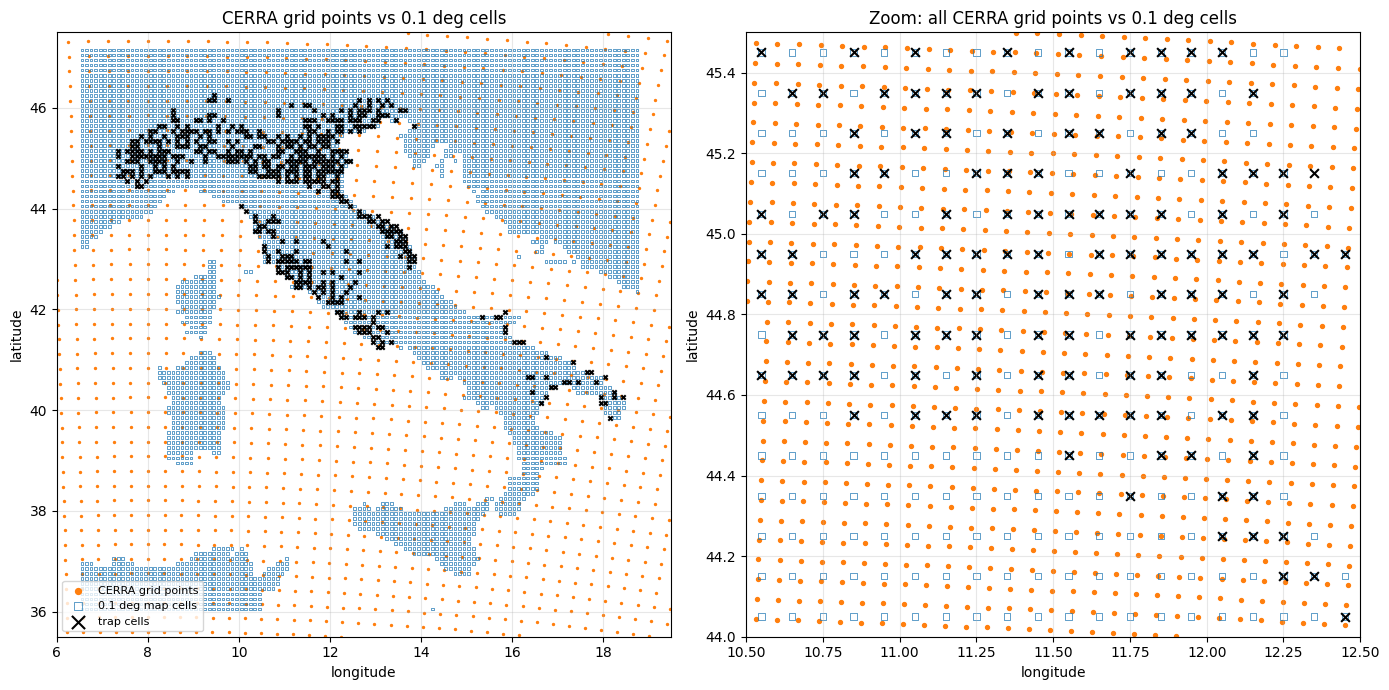

saved /home/u/u301861/Culex-pipens/final_map/figures/grid_overview.png


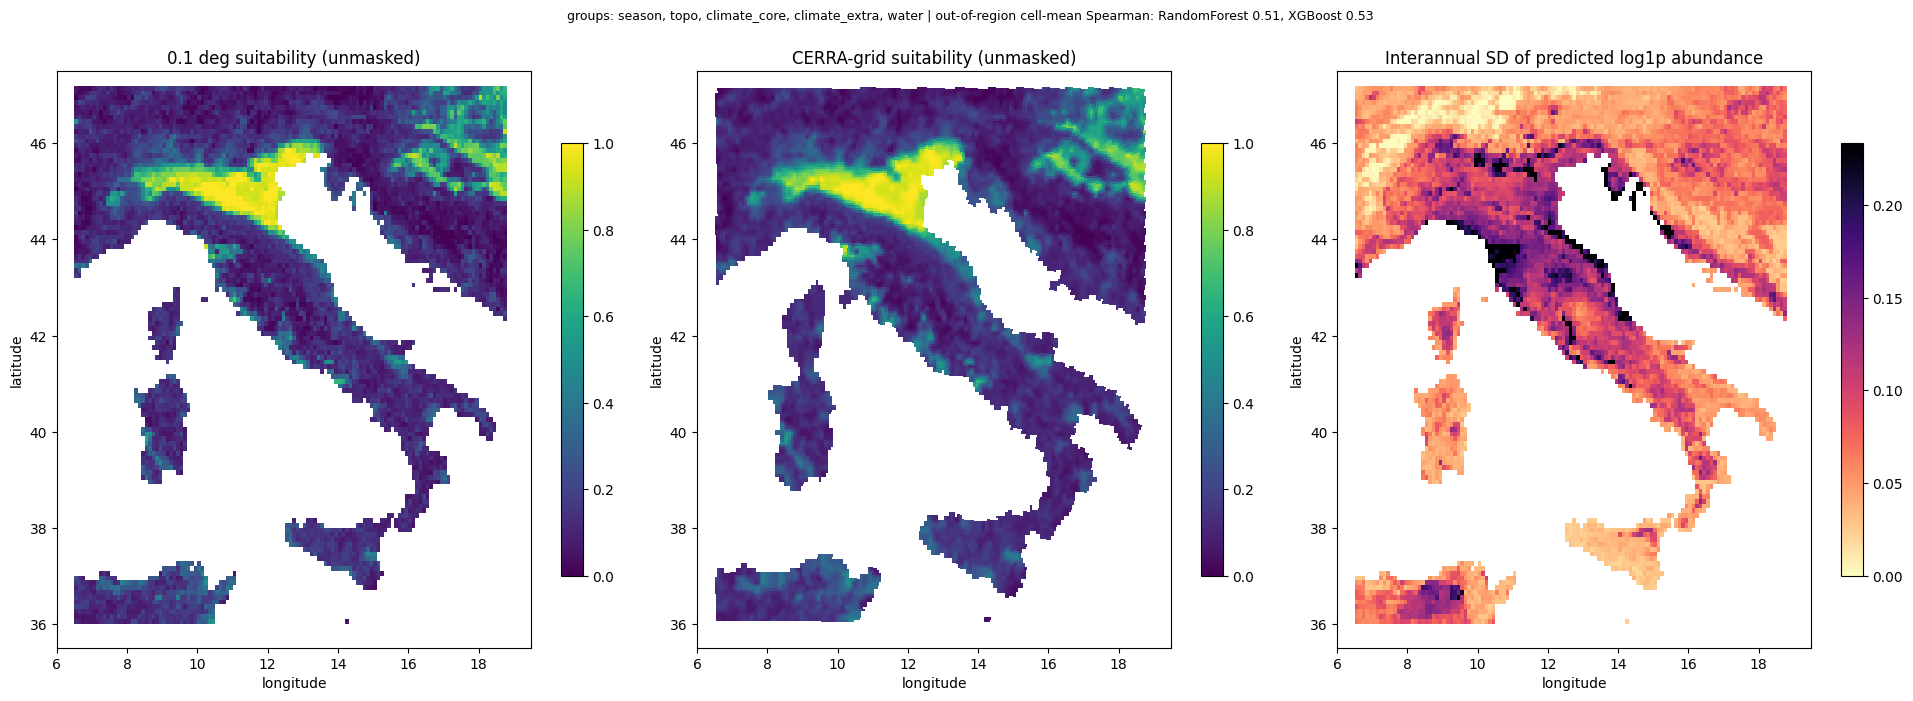

saved /home/u/u301861/Culex-pipens/final_map/figures/suitability_maps.png


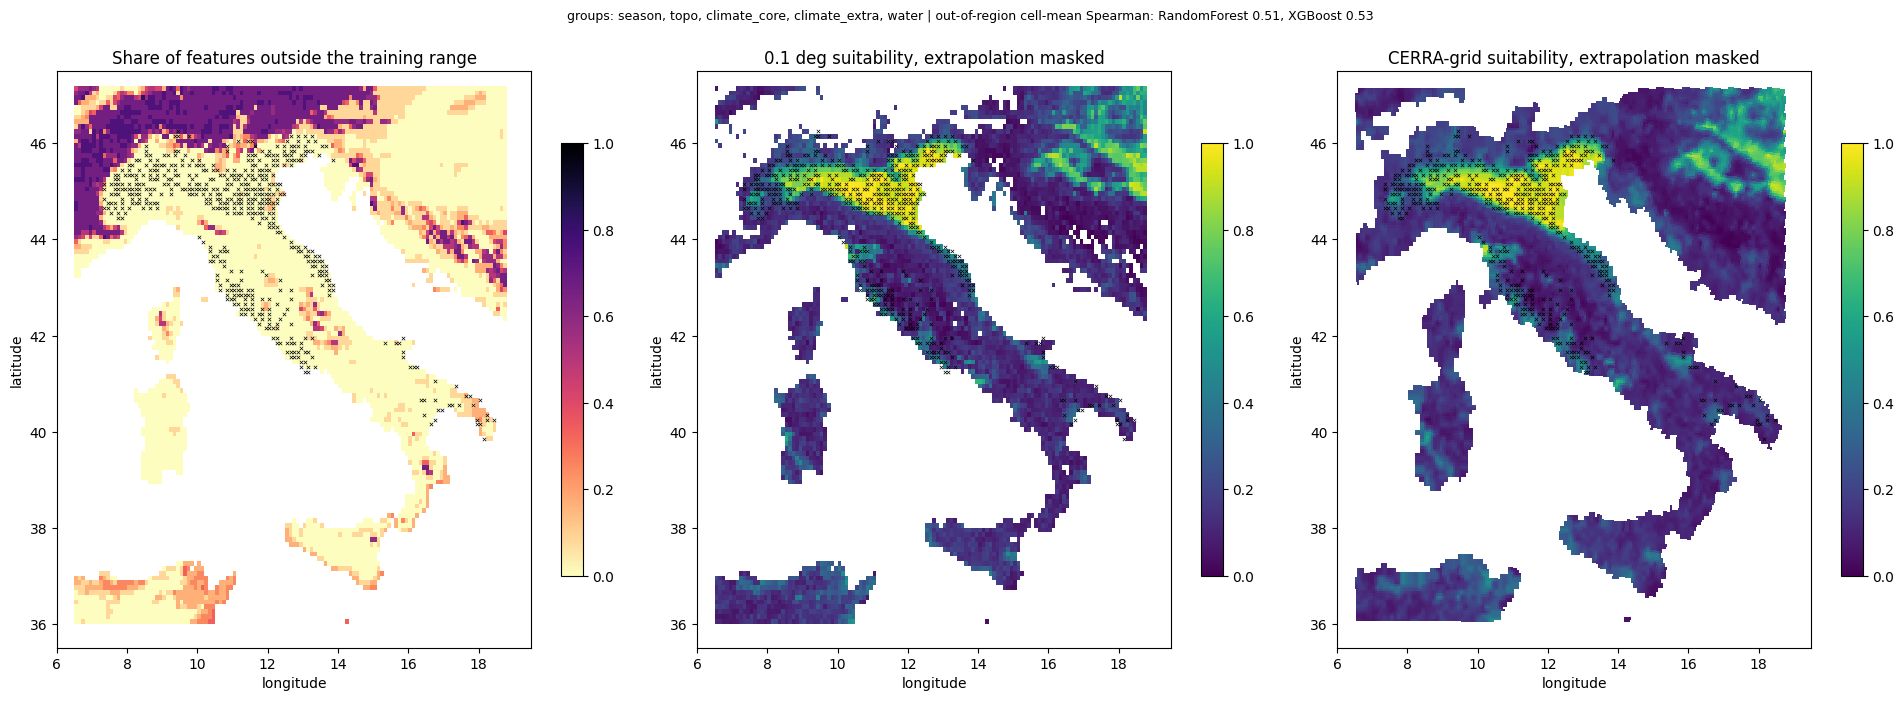

saved /home/u/u301861/Culex-pipens/final_map/figures/extrapolation_maps.png


In [3]:
"""
Culex pipiens (Mission Space): look at the CERRA grid and the suitability maps.

Run after culex_final_map.py. Reads
  * the CERRA grid file (2-D latitude/longitude),
  * the 0.1 deg map  (FINAL_DIR/culex_suitability_0.1deg.nc),
  * the CERRA-grid map (FINAL_DIR/culex_suitability_CERRA.nc), if it exists,
  * final_model_spec.json and final_loro_check.csv (model groups and out-of-region score), if they exist,
  * the trap cells from the training table.

Writes (and, with SHOW_PLOTS = True, shows) in FINAL_DIR/figures:
  grid_overview.png       CERRA grid points, 0.1 deg map cells and trap cells; left = Italy, right = zoom
  suitability_maps.png    0.1 deg suitability, CERRA-grid suitability, interannual spread
  extrapolation_maps.png  share of features outside the training range, and the masked suitability
                          (0.1 deg and CERRA grid); black crosses = trap cells the model was trained on
"""
import os
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ═══════════════════════════════ CONFIG ═══════════════════════════════
BASE = "/work/ch0636/u301861/phd/EURO-CORDEX/EUR-CMIP6/Culex-pipens"
FINAL_DIR = "/home/u/u301861/Culex-pipens/final_map"
TABLE_CSV = f"{BASE}/Culex-pipens_training_table2.csv"
CERRA_GRID_FILE = f"{BASE}/CERRA_File.nc"
CERRA_LAT_NAME, CERRA_LON_NAME = "latitude", "longitude"
BBOX = (6.0, 19.5, 35.5, 47.5)            # lon_min, lon_max, lat_min, lat_max shown in the maps
ZOOM = (10.5, 12.5, 44.0, 45.5)           # zoom window for the grid overview (Po delta region)
OVERLAY_TRAPS = True                      # black crosses on the extrapolation maps
SHOW_PLOTS = True
# ═══════════════════════════════════════════════════════════════════════

FIG_DIR = os.path.join(FINAL_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def finish(fig, name, note=None):
    if note:
        fig.suptitle(note, fontsize=9, y=0.995)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=300)
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)
    print(f"saved {os.path.join(FIG_DIR, name)}.png")


def load_cerra_grid():
    g = xr.open_dataset(CERRA_GRID_FILE)
    lat2, lon2 = np.squeeze(g[CERRA_LAT_NAME].values), np.squeeze(g[CERRA_LON_NAME].values)
    if lat2.ndim == 1:
        lon2, lat2 = np.meshgrid(lon2, lat2)
    lon2 = ((lon2 + 180) % 360) - 180
    return lat2, lon2


def crop(lat2, lon2, box, *arrays):
    """Crop the 2-D CERRA arrays to the rows/columns that touch the box."""
    inside = (lon2 >= box[0]) & (lon2 <= box[1]) & (lat2 >= box[2]) & (lat2 <= box[3])
    rows, cols = np.where(inside.any(axis=1))[0], np.where(inside.any(axis=0))[0]
    sl = (slice(rows.min(), rows.max() + 1), slice(cols.min(), cols.max() + 1))
    return (lat2[sl], lon2[sl]) + tuple(a[sl] for a in arrays)


def spacing_km(lat2, lon2):
    """Median neighbour distance of the CERRA grid in km."""
    j, i = lat2.shape[0] // 2, lat2.shape[1] // 2
    def hav(a, b):
        la1, lo1, la2, lo2 = map(np.radians, (a[0], a[1], b[0], b[1]))
        h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
        return 6371.0 * 2 * np.arcsin(np.sqrt(h))
    return float(np.median([hav((lat2[j, i], lon2[j, i]), (lat2[j, i + 1], lon2[j, i + 1])),
                            hav((lat2[j, i], lon2[j, i]), (lat2[j + 1, i], lon2[j + 1, i]))]))


def model_note():
    """One line saying which model made the maps and how it did out of region."""
    note = []
    sp = os.path.join(FINAL_DIR, "final_model_spec.json")
    if os.path.exists(sp):
        with open(sp) as f:
            spec = json.load(f)
        note.append("groups: " + ", ".join(spec["groups"]))
    cp = os.path.join(FINAL_DIR, "final_loro_check.csv")
    if os.path.exists(cp):
        s = pd.read_csv(cp).groupby("model")["spearman_cell_mean"].mean()
        note.append("out-of-region cell-mean Spearman: " + ", ".join(f"{m} {v:.2f}" for m, v in s.items()))
    return " | ".join(note) if note else None


def draw(panels, name, traps=None):
    fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 7), squeeze=False)
    for ax, (title, x, y, z, cmap, vmin, vmax) in zip(axes[0], panels):
        im = ax.pcolormesh(x, y, np.ma.masked_invalid(z), shading="nearest", cmap=cmap, vmin=vmin, vmax=vmax)
        if traps is not None:
            ax.scatter(traps["longitude"], traps["latitude"], s=6, c="k", marker="x", linewidths=0.5)
        ax.set_xlim(BBOX[0], BBOX[1]); ax.set_ylim(BBOX[2], BBOX[3])
        ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
        plt.colorbar(im, ax=ax, shrink=0.75)
    finish(fig, name, model_note())


# ───────────────────────── grid overview ─────────────────────────
lat2, lon2 = load_cerra_grid()
print(f"CERRA grid: shape {lat2.shape}, neighbour spacing about {spacing_km(lat2, lon2):.1f} km")
n_in = int(((lon2 >= BBOX[0]) & (lon2 <= BBOX[1]) & (lat2 >= BBOX[2]) & (lat2 <= BBOX[3])).sum())
print(f"CERRA cells inside the plotted box: {n_in}")

trap = None
if os.path.exists(TABLE_CSV):
    trap = pd.read_csv(TABLE_CSV, usecols=["cell_id", "longitude", "latitude"]).drop_duplicates("cell_id")
cells_path = os.path.join(FINAL_DIR, "map_cells.csv")
mcells = pd.read_csv(cells_path) if os.path.exists(cells_path) else None

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, box, step, title in [(axes[0], BBOX, 6, "CERRA grid points vs 0.1 deg cells"),
                             (axes[1], ZOOM, 1, "Zoom: all CERRA grid points vs 0.1 deg cells")]:
    la2, lo2 = lat2[::step, ::step], lon2[::step, ::step]          # stride rows AND columns (keeps the grid look)
    m = (lo2 >= box[0]) & (lo2 <= box[1]) & (la2 >= box[2]) & (la2 <= box[3])
    ax.scatter(lo2[m], la2[m], s=2 if step > 1 else 8, c="tab:orange", label="CERRA grid points")
    if mcells is not None:
        mm = mcells[(mcells["longitude"].between(box[0], box[1])) & (mcells["latitude"].between(box[2], box[3]))]
        ax.scatter(mm["longitude"], mm["latitude"], s=4 if step > 1 else 20, marker="s", facecolors="none",
                   edgecolors="tab:blue", linewidths=0.5, label="0.1 deg map cells")
    if trap is not None:
        tt = trap[(trap["longitude"].between(box[0], box[1])) & (trap["latitude"].between(box[2], box[3]))]
        ax.scatter(tt["longitude"], tt["latitude"], s=10 if step > 1 else 40, c="k", marker="x", label="trap cells")
    ax.set_xlim(box[0], box[1]); ax.set_ylim(box[2], box[3])
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.grid(alpha=0.3)
axes[0].legend(markerscale=3, fontsize=8, loc="lower left")
finish(fig, "grid_overview")

# ───────────────────────── suitability and extrapolation maps ─────────────────────────
p01 = os.path.join(FINAL_DIR, "culex_suitability_0.1deg.nc")
pc = os.path.join(FINAL_DIR, "culex_suitability_CERRA.nc")
g = xr.open_dataset(p01) if os.path.exists(p01) else None
c = xr.open_dataset(pc) if os.path.exists(pc) else None
if c is None:
    print("culex_suitability_CERRA.nc not found: run culex_final_map.py with CERRA_GRID_FILE set.")


def p_01(var, title, cmap, vmin, vmax):
    return (title, g["lon"].values, g["lat"].values, g[var].values, cmap, vmin, vmax)


def p_cerra(var, title, cmap, vmin, vmax):
    cl, co = np.squeeze(c["latitude"].values), np.squeeze(c["longitude"].values)
    cl, co, z = crop(cl, co, BBOX, np.squeeze(c[var].values))
    return (title, co, cl, z, cmap, vmin, vmax)


# figure 1: the suitability itself (unmasked), in both grids, and how much it varies between weather years
panels = []
if g is not None:
    panels.append(p_01("suitability", "0.1 deg suitability (unmasked)", "viridis", 0, 1))
if c is not None and "suitability" in c:
    panels.append(p_cerra("suitability", "CERRA-grid suitability (unmasked)", "viridis", 0, 1))
if g is not None and "interannual_sd" in g:
    sd = g["interannual_sd"].values
    panels.append(p_01("interannual_sd", "Interannual SD of predicted log1p abundance", "magma_r", 0,
                       float(np.nanpercentile(sd, 98))))
if panels:
    draw(panels, "suitability_maps")

# figure 2: where the map extrapolates, and the masked suitability (what to submit if the mask is used)
panels = []
if g is not None and "outside_frac" in g:
    panels.append(p_01("outside_frac", "Share of features outside the training range", "magma_r", 0, 1))
if g is not None and "suitability_masked" in g:
    panels.append(p_01("suitability_masked", "0.1 deg suitability, extrapolation masked", "viridis", 0, 1))
if c is not None and "suitability_masked" in c:
    panels.append(p_cerra("suitability_masked", "CERRA-grid suitability, extrapolation masked", "viridis", 0, 1))
if panels:
    draw(panels, "extrapolation_maps", traps=trap if OVERLAY_TRAPS else None)
else:
    print("no outside_frac / suitability_masked variables found: rerun the adapted culex_final_map.py")